# Optional 3-D pharmacophore matching

Conformer generation and Pharm3D / EmbedLib matching are much slower than 2-D SMARTS profiling. This notebook uses them on a shortlist: gefitinib as the reference, a handful of other EGFR actives, and a handful of decoys. The goal is to show the API, not to screen the full 3,000-compound subset.

In [1]:
from rdkit import Chem
from rdkit.Chem import Draw
from pharmprof.data import load_egfr
from pharmprof.patterns import feature_factory
from pharmprof.pharm3d import (
    generate_conformers,
    features_for_conformer,
    pharmacophore_from_reference,
    match_pharmacophore,
)
from pharmprof.io import MolRecord

data = load_egfr(subset=True)
# gefitinib is DUD-E id 88232 / CHEMBL939
ref_row = data.loc[data.mol_id.astype(str) == "88232"].iloc[0]
ref = Chem.MolFromSmiles(ref_row.smiles)
ref3d = generate_conformers(ref, n_confs=5, random_seed=1)
print("reference conformers:", ref3d.GetNumConformers())

factory = feature_factory("basefeatures")
feats = features_for_conformer(ref3d, factory, conf_id=0)
for f in feats:
    print(f"{f.GetFamily():16s}  {f.GetType():20s}  atoms={list(f.GetAtomIds())}")

/workspace/venvs/pharmprof/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


reference conformers: 5
Donor             SingleAtomDonor       atoms=[9]
Donor             SingleAtomDonor       atoms=[25]
Acceptor          SingleAtomAcceptor    atoms=[1]
Acceptor          SingleAtomAcceptor    atoms=[5]
Acceptor          SingleAtomAcceptor    atoms=[7]
Acceptor          SingleAtomAcceptor    atoms=[14]
Acceptor          SingleAtomAcceptor    atoms=[21]
Acceptor          SingleAtomAcceptor    atoms=[28]
PosIonizable      BasicGroup            atoms=[25]
Aromatic          Arom6                 atoms=[2, 3, 4, 18, 19, 20]
Aromatic          Arom6                 atoms=[4, 5, 6, 7, 8, 18]
Aromatic          Arom6                 atoms=[10, 11, 12, 13, 15, 17]
Hydrophobe        ThreeWayAttach        atoms=[3]
Hydrophobe        ThreeWayAttach        atoms=[11]
Hydrophobe        ThreeWayAttach        atoms=[12]
Hydrophobe        ThreeWayAttach        atoms=[15]
Hydrophobe        ThreeWayAttach        atoms=[17]
Hydrophobe        ThreeWayAttach        atoms=[18]
Hydrophobe 

Build a compact pharmacophore from the Donor, Acceptor, Aromatic and PosIonizable sites on conformer 0, with ±1.5 Å distance bounds, and try to match a few actives and decoys.

In [2]:
pharm, used = pharmacophore_from_reference(
    ref3d, factory,
    families=["Donor", "Acceptor", "Aromatic", "PosIonizable"],
    tolerance=1.5, conf_id=0,
)
print(f"pharmacophore sites: {len(used)}")

actives = data.loc[data.label == 1].head(6)
decoys = data.loc[data.label == 0].head(6)
shortlist = pd_concat = __import__("pandas").concat([actives, decoys], ignore_index=True)
lib = [
    MolRecord(str(r.mol_id), r.smiles, Chem.MolFromSmiles(r.smiles), int(r.label))
    for r in shortlist.itertuples()
]
hits = match_pharmacophore(lib, pharm, factory, generate=True, n_confs=5, random_seed=1, progress=True)
hits["label"] = [r.label for r in lib]
hits

pharmacophore sites: 12


pharm3d: 100%|██████████| 12/12 [00:01<00:00,  6.41it/s]


,mol_id,smiles,matched,n_feature_matches,embedded,error,label
0,101343,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,False,0,False,,1
1,81022,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,False,0,False,,1
2,101370,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,1
3,290482,Cn1cnc2cc3ncnc(Nc4cccc(Br)c4)c3cc21,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,1
4,299120,CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2...,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,1
5,81739,CN(C)c1cc2ncnc(Nc3cccc(Br)c3)c2cn1,False,0,False,,1
6,C59746490,COc1ccccc1[C@@H](CNS(=O)(=O)c1ccc2c(c1)CCC(=O)...,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,0
7,C36775306,Cc1[nH+]c(SCC(=O)NN2C(=O)N[C@@](C)(c3ccccc3)C2...,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,0
8,C64414522,COc1ccccc1C1=C[C@@H](C(=O)NCC2CCC([C@H]3Nc4ccc...,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,0
9,C20573605,CSCC[C@H](NC(=O)CCCc1ccccc1)C(=O)N1CCC2(CC1)NC...,True,12,False,embed failed: AttributeError: module 'rdkit.Ch...,0


A `matched` flag means EmbedLib found a mapping of the pharmacophore features onto the ligand. `embedded` means a 3-D embedding consistent with the distance bounds was produced. Failures are recorded in `error` rather than raised — EmbedLib is picky, which is one reason this path stays optional.

       matched  embedded
label                   
0            5         0
1            3         0


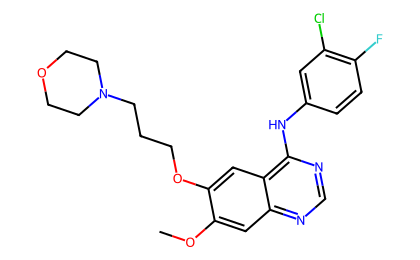

In [3]:
print(hits.groupby("label")[["matched", "embedded"]].sum())
# redraw the reference with 2-D coords for a visual check
from rdkit.Chem import rdDepictor
vis = Chem.Mol(ref)
rdDepictor.Compute2DCoords(vis)
Draw.MolToImage(vis, size=(420, 260))